# EMOS

Censored-normal EMOS fitted on the train fold and checked on the validation fold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.splits import training_rows, evaluation_rows
from windai.models.EMOS import EMOS
from windai.models.baselines import Climatology, RawEnsemble
from windai.evaluation.evaluate import score
from windai.evaluation.scoring import pit_from_quantiles

pd.set_option("display.width", 200)
df, curve = load_dataset("train", fit="val")
train, val = training_rows(df, "val"), evaluation_rows(df, "val")
hidden = val.drop(columns=["power", "cf"])
models = {"emos": EMOS().fit(train), "raw_ensemble": RawEnsemble().fit(train), "climatology": Climatology().fit(train)}
fc = {name: m.predict(hidden) for name, m in models.items()}
y = val["power"].to_numpy()
obs = ~np.isnan(y)
print(len(train), "train rows,", len(val), "val rows")

104946 train rows, 34080 val rows


## Fitted parameters

In [2]:
p = models["emos"].summary()
print("all converged:", bool(p["converged"].all()), "| rows per model:", p["n"].min(), "-", p["n"].max())
p.groupby("zone")[["a", "b", "c", "d"]].describe().loc[:, (slice(None), ["min", "50%", "max"])].round(3)

all converged: True | rows per model: 1092 - 1094


a                    b                    c                    d              
              min    50%    max    min    50%    max    min    50%    max    min    50%    max
zone                                                                                          
ELSPOT NO1 -0.102 -0.023  0.027  1.022  1.071  1.114  0.103  0.118  0.134  0.987  1.321  1.949
ELSPOT NO2 -0.065 -0.007  0.022  1.015  1.040  1.061  0.060  0.075  0.086  0.963  1.058  1.182
ELSPOT NO3 -0.037 -0.005  0.016  0.973  1.020  1.037  0.049  0.069  0.083  1.048  1.191  1.393
ELSPOT NO4 -0.012  0.002  0.013  1.020  1.038  1.064  0.082  0.091  0.100  0.811  1.066  1.330

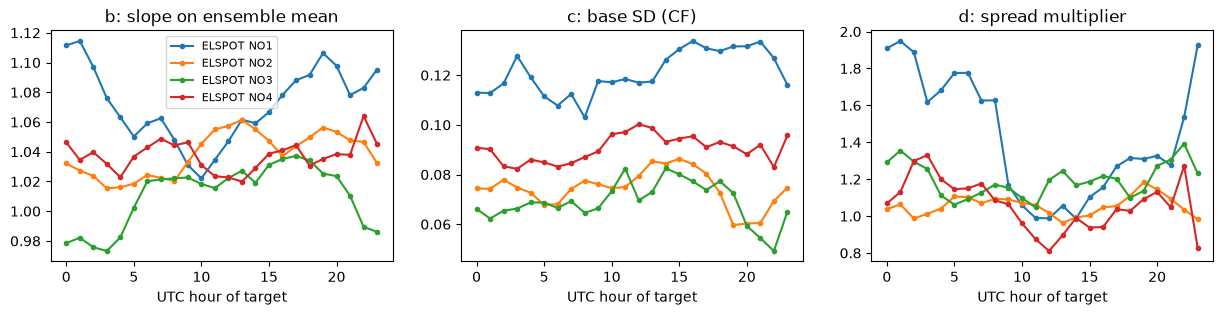

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for zone, g in p.groupby(level="zone"):
    hours = g.index.get_level_values("target_hour_utc")
    for ax, col in zip(axes, ["b", "c", "d"]):
        ax.plot(hours, g[col], marker=".", label=zone)
for ax, col, what in zip(axes, ["b", "c", "d"], ["slope on ensemble mean", "base SD (CF)", "spread multiplier"]):
    ax.set_title(f"{col}: {what}"); ax.set_xlabel("UTC hour of target")
axes[0].legend(fontsize=8)
plt.show()

All 96 fits (4 zones × 24 UTC hours) converged, and the parameters vary smoothly over the day. The location is close to the ensemble mean (a ≈ 0, b ≈ 1.0–1.1). Most of the added spread comes from the constant term c (0.05–0.13 CF), an error that is present even when the members agree.

## Calibration on val

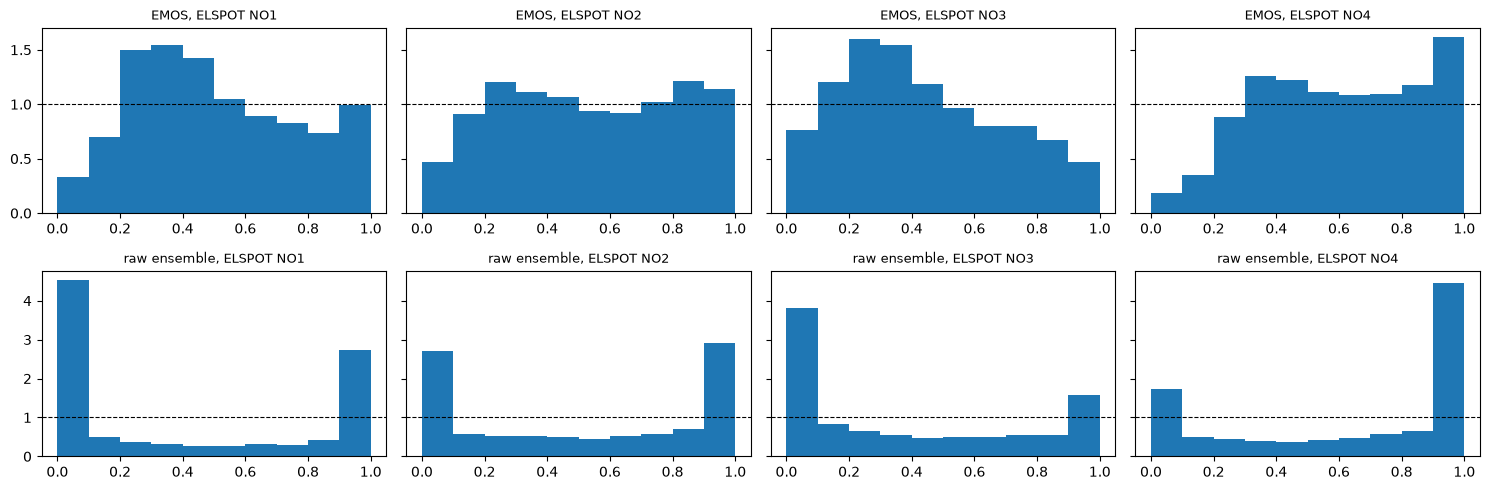

In [4]:
pit_emos = fc["emos"].pit_fn(y[obs], rng=0)
pit_raw = pit_from_quantiles(fc["raw_ensemble"].quantiles[obs], fc["raw_ensemble"].levels, y[obs], rng=0)
zones = val["zone"].to_numpy()[obs]
fig, axes = plt.subplots(2, 4, figsize=(15, 5), sharey="row")
for j, zone in enumerate(sorted(set(zones))):
    for i, (name, pit) in enumerate([("EMOS", pit_emos), ("raw ensemble", pit_raw)]):
        axes[i, j].hist(pit[zones == zone], bins=10, range=(0, 1), density=True)
        axes[i, j].axhline(1, color="k", lw=0.8, ls="--")
        axes[i, j].set_title(f"{name}, {zone}", fontsize=9)
plt.tight_layout(); plt.show()

In [5]:
# Share of the PIT in the outer tenths and in the middle fifth: 0.2 and 0.2 for a calibrated forecast
def tails_mid(pit):
    return pd.Series({"outer tenths": ((pit < 0.1) | (pit > 0.9)).mean(), "middle fifth": ((pit > 0.4) & (pit < 0.6)).mean(),
                      "mean PIT": pit.mean()})
pd.DataFrame({f"{n} {z}": tails_mid(pit[zones == z]) for n, pit in [("emos", pit_emos), ("raw", pit_raw)]
              for z in sorted(set(zones))}).T.round(3)

,outer tenths,middle fifth,mean PIT
emos ELSPOT NO1,0.133,0.248,0.504
emos ELSPOT NO2,0.161,0.201,0.535
emos ELSPOT NO3,0.123,0.215,0.436
emos ELSPOT NO4,0.181,0.234,0.598
raw ELSPOT NO1,0.726,0.053,0.407
raw ELSPOT NO2,0.561,0.096,0.516
raw ELSPOT NO3,0.540,0.097,0.377
raw ELSPOT NO4,0.617,0.080,0.644


The raw ensemble's PIT is strongly U-shaped (54–73 % of the observations in the outer tenths), i.e. far too narrow. EMOS is close to calibrated and slightly too wide (coverage 57 / 85 / 92 / 96 % at 50 / 80 / 90 / 95 %). It is biased on val in NO3 (over-forecast) and NO4 (under-forecast), as the raw ensemble is, which points to a shift between the training and validation periods.

## Skill against climatology

In [6]:
def crps_table(name):
    t = score(fc[name], y, by=("zone", "issue_hour"))
    t = t.loc[t.index.get_level_values(0) != "all", "crps_q"]
    overall = score(fc[name], y)["crps_q"]
    return pd.concat([t, overall.rename(lambda z: (z, "all"))])

crps = pd.DataFrame({n: crps_table(n) for n in fc})
crpss = pd.DataFrame({"raw_ensemble": 1 - crps["raw_ensemble"] / crps["climatology"],
                      "emos": 1 - crps["emos"] / crps["climatology"],
                      "emos vs raw (CRPS change %)": 100 * (crps["emos"] / crps["raw_ensemble"] - 1)})
crpss.round(3)

raw_ensemble   emos  emos vs raw (CRPS change %)
ELSPOT NO1 9           0.306  0.398                      -13.315
           12          0.069  0.321                      -27.074
ELSPOT NO2 9           0.520  0.561                       -8.430
           12          0.541  0.598                      -12.391
ELSPOT NO3 9           0.508  0.539                       -6.334
           12          0.463  0.514                       -9.423
ELSPOT NO4 9           0.266  0.393                      -17.339
           12          0.470  0.533                      -12.011
ELSPOT NO1 all         0.205  0.365                      -20.159
ELSPOT NO2 all         0.529  0.577                      -10.108
ELSPOT NO3 all         0.489  0.529                       -7.684
ELSPOT NO4 all         0.358  0.457                      -15.357
all        all         0.458  0.520                      -11.421

EMOS beats the raw ensemble in every zone and at both issue times, with 6–27 % lower CRPS. The overall CRPSS against climatology is 0.52, against 0.46 for the raw ensemble. The gain is largest where the raw ensemble is weakest (NO1).